# 11.2 - GRG Policy Objective Comparison

Executed analysis of saved experiments. The three full missions were run separately; this Notebook verifies and visualizes their artifacts without rerunning them.

In [1]:
from pathlib import Path
import json, hashlib
import numpy as np
from IPython.display import display, Image, Markdown
root = Path.cwd()
assert (root / 'testing_code/config.json').is_file()
run = root / '11.2_result/run_20261103T020926Z'
read = lambda p: json.loads(p.read_text())
protocol = read(run / 'protocol.json')
print('Pinned run:', run.name)
print('Weights:', protocol['comparison_config']['fusion_weights'])
print('Target points:', protocol['catalog']['target_count'])
print('Target time (h):', protocol['catalog']['target_h'])

Pinned run: run_20261103T020926Z
Weights: {'mi': 0.5, 'emse_reduction': 0.5}
Target points: 1393
Target time (h): 72.25


## Hypothesis and fixed protocol

Only the route-scoring objective changes. GRG depth, timing, history, kernel parameters, navigation and record acquisition stay fixed. EMSE targets mean latent variance over a fixed-deadline reachable grid. The held-out temperature references are separate, nonsimultaneous real observations. Both components are computed in every arm.

## Normalized 50/50 fusion

`J = 0.5 * MI / s_MI + 0.5 * EMSE_reduction / s_EMSE`. Each scale is a maximum initial single-event gain, frozen before acquisition. No clipping, outcome-based tuning or optimal-weight claim. All recursive scores use the configured objective.

In [2]:
for name in ['unit_tests.json','numerical_verification.json','mi_baseline_verification.json','verification.json']:
    result = read(run / name)
    assert result['passed'], name
    print(name, 'PASSED')
for relative, digest in read(run / 'artifacts_sha256.json').items():
    assert hashlib.sha256((run / relative).read_bytes()).hexdigest() == digest, relative
print('All original run artifact hashes match.')

unit_tests.json PASSED
numerical_verification.json PASSED
mi_baseline_verification.json PASSED
verification.json PASSED
All original run artifact hashes match.


## Measured results

RMSE and MAE use the same 28 held-out measured records; target variance is a model quantity over the fixed grid. These are not interchangeable scores.

| Policy | Samples | Held-out RMSE (C) | MAE (C) | Target mean variance (C^2) | Joint MI (nats) | Planning wall time (s) |
|---|---:|---:|---:|---:|---:|---:|
| GRG + MI | 7 | 0.546907 | 0.417031 | 0.461534 | 2.152729 | 3.555 |
| GRG + EMSE | 7 | 0.527523 | 0.362148 | 0.408739 | 1.839464 | 2.253 |
| GRG + fusion (50/50) | 7 | 0.496601 | 0.379663 | 0.399477 | 2.063027 | 2.866 |

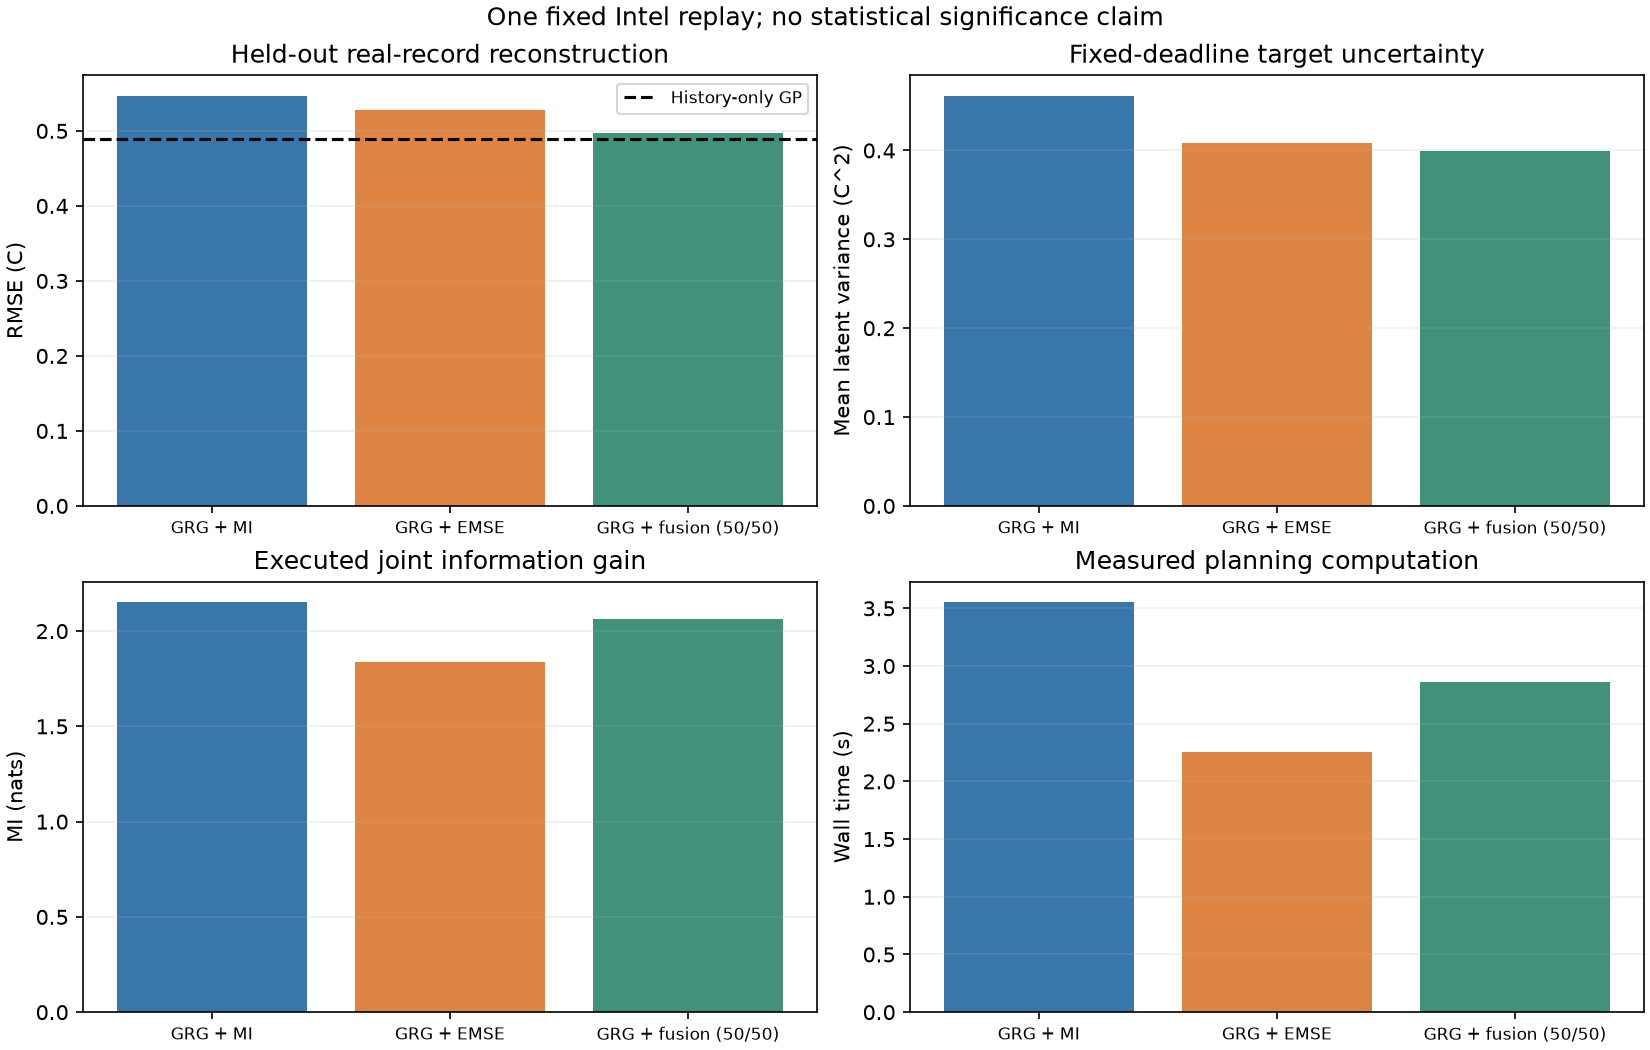

In [3]:
display(Markdown('| Policy | Samples | Held-out RMSE (C) | MAE (C) | Target mean variance (C^2) | Joint MI (nats) | Planning wall time (s) |\n|---|---:|---:|---:|---:|---:|---:|\n| GRG + MI | 7 | 0.546907 | 0.417031 | 0.461534 | 2.152729 | 3.555 |\n| GRG + EMSE | 7 | 0.527523 | 0.362148 | 0.408739 | 1.839464 | 2.253 |\n| GRG + fusion (50/50) | 7 | 0.496601 | 0.379663 | 0.399477 | 2.063027 | 2.866 |'))
display(Image(filename=str(run / 'figures/comparison.png')))

## Executed simulated paths

Only the objective changes the selected destinations; the reused grid navigator executes every leg. Temperature values come from distinct recorded sensor rows at their original times.

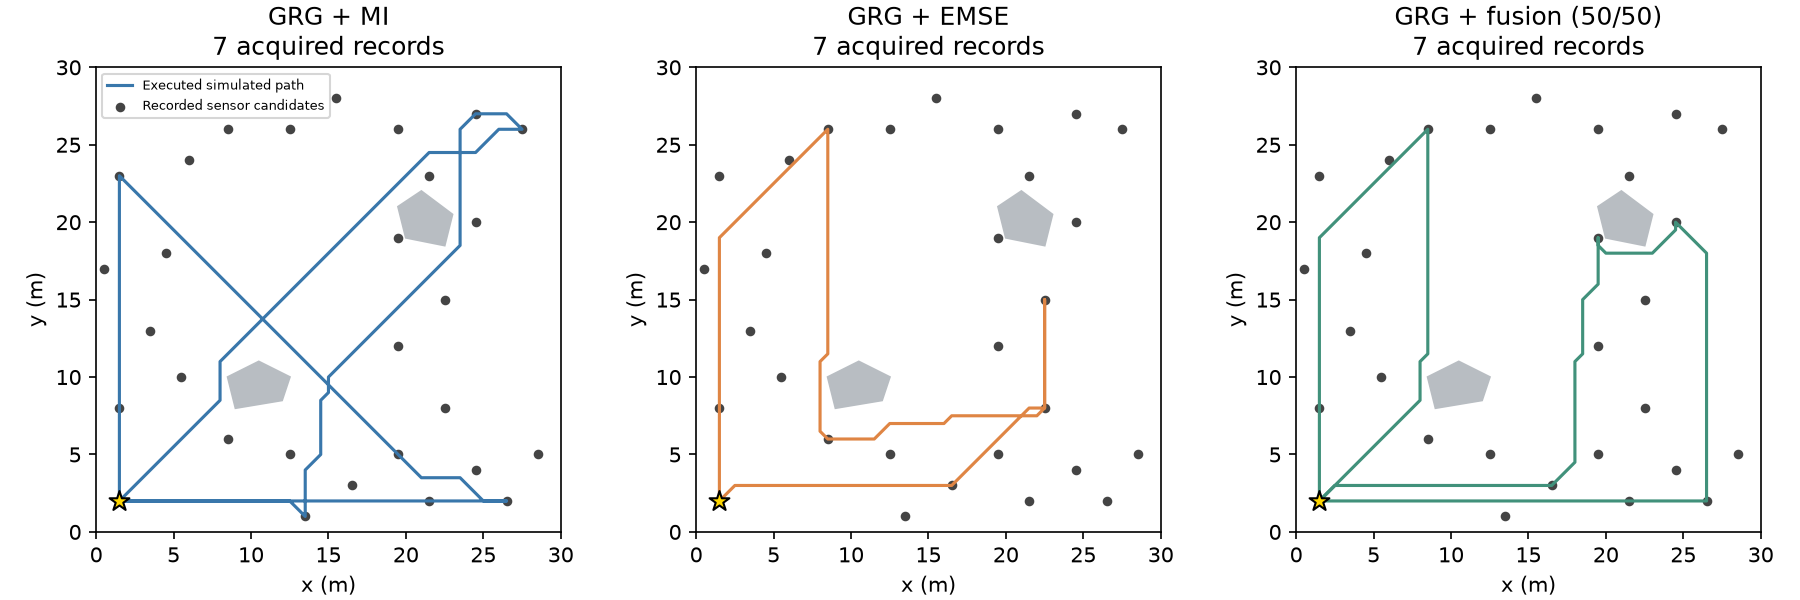

In [4]:
display(Image(filename=str(run / 'figures/routes.png')))

## Fixed-deadline GP predictions

These are predictions and latent standard deviations, not measured dense-field ground truth. Color scales are shared between policy panels.

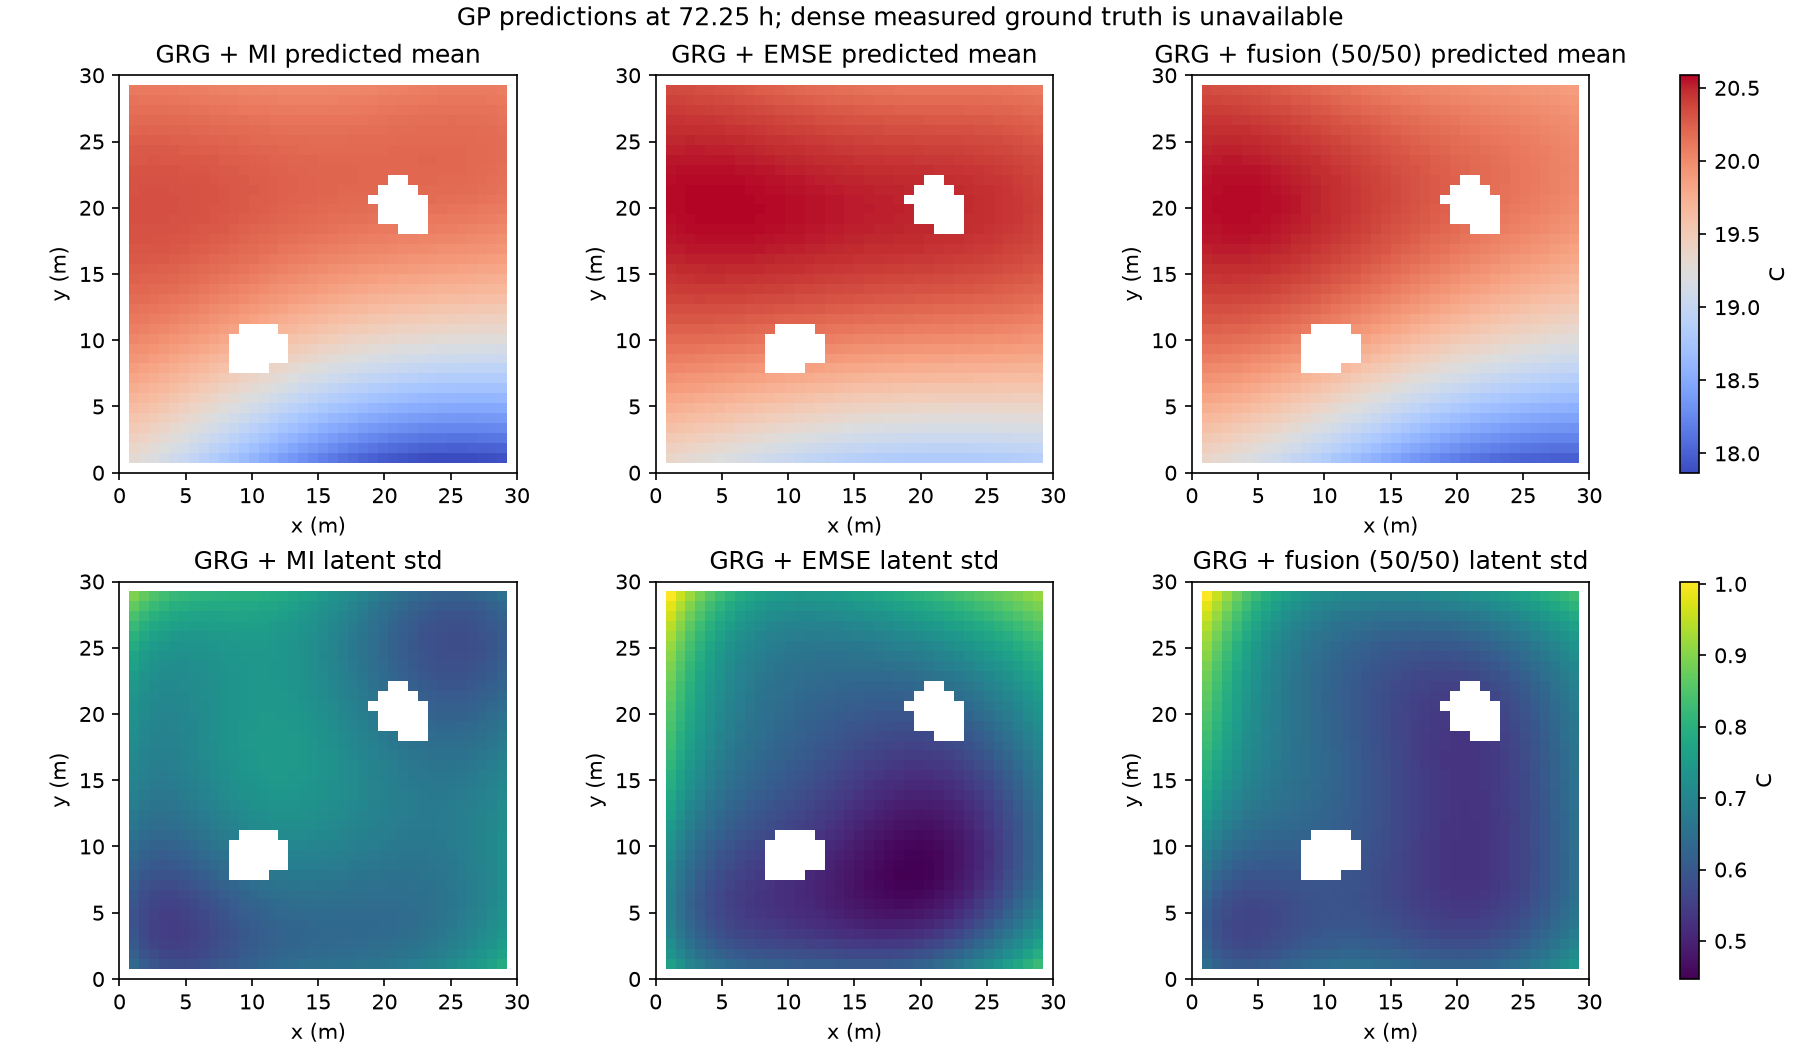

In [5]:
display(Image(filename=str(run / 'figures/target_predictions.png')))

## Independent replay of saved metrics

In [6]:
for policy in protocol['comparison_config']['policies']:
    summary = read(run / policy / 'summary.json')
    with np.load(run / policy / 'reference_predictions.npz') as saved:
        error = saved['final_mean'] - saved['truth']
        rmse = float(np.sqrt(np.mean(error**2)))
        mae = float(np.mean(np.abs(error)))
    assert np.isclose(rmse, summary['final_metrics']['rmse_c'], atol=1e-10)
    assert np.isclose(mae, summary['final_metrics']['mae_c'], atol=1e-10)
    with np.load(run / policy / 'target_predictions.npz') as saved:
        variance = float(saved['final_variance'].mean())
    assert np.isclose(variance, summary['final_mean_target_variance_c2'], atol=1e-10)
    print(policy, 'RMSE:', round(rmse, 6), 'MAE:', round(mae, 6), 'target variance:', round(variance, 6))

mi RMSE: 0.546907 MAE: 0.417031 target variance: 0.461534
emse RMSE: 0.527523 MAE: 0.362148 target variance: 0.408739
fusion RMSE: 0.496601 MAE: 0.379663 target variance: 0.399477


## Interpretation

On this single recorded replay, GRG + fusion (50/50) has the lowest held-out RMSE (0.496601 C), while GRG + fusion (50/50) has the lowest target mean variance (0.399477 C^2). These are different quantities. This is one fixed dataset and mission window, not evidence of statistical superiority. No policy lowers RMSE below the history-only GP in this run.

The original mission clock excludes computation. Wall-time diagnostics are reported separately, so successful replay is not a real-time deployment claim. This comparison does not establish future-forecast accuracy, optimal fusion weights, or a new GRG approximation guarantee. Kernel changes, continuous acquisition and ROS/Nav2 integration are outside this experiment.